# 01 · Preprocessing — Rendeiro 2020 Chronic Lymphocytic Leukemia (malignant compartment)

Isolate malignant CLL B-cells, threshold thin samples by a **data-driven multiplicative count gap**,
integrate patients/timepoints (Harmony on `sample`), embed, remove detached islands, and read **Gate 1**
(sample-mixing + manifold continuity) off the **regenerated embedding** plus a per-neighbourhood metric
(iLISI) across an integration-strength sweep — never a scalar alone.

Rendeiro 2020 is a **longitudinal** 10x study of chronic lymphocytic leukemia: 4 patients
(CLL1/CLL5/CLL6/CLL8) sampled across ibrutinib-treatment timepoints (d0..d280), 12 samples total.
The malignant cells are mature CLL B-cell clones. Because each patient's clone carries private
IGHV/BCR rearrangements and CNVs, raw per-patient segregation is expected and strong Harmony
integration is required. **The decisive Gate-1 question is not whether the clones can be forced
together, but whether a shared developmental axis exists *within* each patient** — settled here before
the GO. Every tunable choice is derived from this dataset. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Rendeiro2020_Hematologic-4
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the re-analysis suffix ('-4')
raw_name = 'Data_' + re.sub(r'-\d+$', '', name)
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Rendeiro2020_Hematologic-4 | category: Hematologic | raw: Data_Rendeiro2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), `normalize_total` + `log1p`, and labels
malignant cells from the publication `cell_type` annotation. We keep the malignant CLL B-cells and drop
the normal PBMC compartment (T/NK/macrophage).

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant raw:', adata.shape[0], '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('patients:', adata.obs['patient'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas: (48016, 18402)
cell types: {'Malignant': 18854, 'T_NK_cell': 6954, 'Macrophage': 2246, 'T_cell': 1455, 'NK_cell': 569}
malignant raw: 18854 | samples: 11 | patients: 4
patients: {'CLL5': 7972, 'CLL6': 6973, 'CLL1': 2273, 'CLL8': 1636}
expression: X max 6.35 (log1p of normalize_total UMI counts)


### Sample threshold — data-driven multiplicative gap
Sort per-sample malignant counts and locate the largest **multiplicative** drop. A genuine
spillover/thin-sample cliff is a >3x drop; keep samples above the geometric-mean cut.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
CLIFF = 3.0
print('sorted per-sample counts:', dict(zip(n.index, n.values)))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); cliff = {CLIFF}x; geom-mean cut = {thresh}')
if ratios[gap] >= CLIFF:
    keep = n.index[n >= 100]      # cut sits far above 100; the >=100 floor selects the same 7 samples
    print(f'clean cliff (ratio {ratios[gap]:.2f}) -> keep samples with >=100 cells (below the {int(vals[gap+1])}-cell cliff)')
else:
    keep = n.index
    print('no clean cliff -> keep all samples')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells across {adata.obs["patient"].nunique()} patients')
print('kept samples:', adata.obs['sample'].value_counts().to_dict())

sorted per-sample counts: {'CLL5_d0': np.int64(5074), 'CLL6_d30': np.int64(4353), 'CLL5_d30': np.int64(2818), 'CLL1_d0': np.int64(2267), 'CLL6_d120': np.int64(1575), 'CLL8_d0': np.int64(1558), 'CLL6_d0': np.int64(1012), 'CLL5_d150': np.int64(80), 'CLL8_d30': np.int64(78), 'CLL6_d280': np.int64(33), 'CLL1_d120': np.int64(6)}
largest multiplicative gap: 1012 -> 80 (ratio 12.65); cliff = 3.0x; geom-mean cut = 284
clean cliff (ratio 12.65) -> keep samples with >=100 cells (below the 80-cell cliff)
kept 7/11 samples -> 18657 cells across 4 patients
kept samples: {'CLL5_d0': 5074, 'CLL6_d30': 4353, 'CLL5_d30': 2818, 'CLL1_d0': 2267, 'CLL6_d120': 1575, 'CLL8_d0': 1558, 'CLL6_d0': 1012}


### Cell-cycle scoring
CLL blasts are a proliferating population; score the cell cycle (Tirosh/Regev S and G2/M gene sets)
so proliferation can be tested for orthogonality to the embryonic axis in 02 (a cycling compartment
with Gast confounded by proliferation is *not* the embryonic axis).

In [5]:
S_GENES=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
G2M_GENES=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in S_GENES if g in adata.var_names],
                             g2m_genes=[g for g in G2M_GENES if g in adata.var_names])
adata.obs['cyc_score'] = np.maximum(adata.obs['S_score'].fillna(0), adata.obs['G2M_score'].fillna(0))
adata.obs['cell_cycle_phase'] = adata.obs['phase']
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())
print('cycling fraction (S+G2M): %.3f' % adata.obs['phase'].isin(['S','G2M']).mean())

cell-cycle phase: {'G1': 10488, 'S': 7376, 'G2M': 793}
cycling fraction (S+G2M): 0.438


### Gene filter, overdispersion, PCA

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 528


### Gate 1 — integration-strength sweep with a per-neighbourhood metric
The samples are longitudinal timepoints of only 4 patients, so `sample` iLISI mixes within-patient
timepoints; we report **both** `sample` iLISI (of 7) and the stricter `patient` iLISI (of 4). Pre-Harmony
the clones are fully segregated (iLISI 1.0). We sweep theta and select the integration where mixing
plateaus without collapsing the manifold.

In [7]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L=codes[idx]; out=np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt=np.unique(L[i],return_counts=True); p=cnt/k; out[i]=1.0/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; pat = adata.obs['patient'].values
nsamp = adata.obs['sample'].nunique(); npat = adata.obs['patient'].nunique()
il_pre_s = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
il_pre_p = np.median(ilisi(adata.obsm['X_pca'][:,:20], pat))
print(f'pre-Harmony iLISI median: sample {il_pre_s:.2f}/{nsamp}, patient {il_pre_p:.2f}/{npat} (fully clone-segregated)')
for th in [1,2,3,5,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    ils = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp))
    ilp = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], pat))
    print(f'  theta={th:2d}: sample iLISI={ils:.2f}/{nsamp}  patient iLISI={ilp:.2f}/{npat}')
theta = 5
print('selected theta =', theta, '(mixing near-plateau; strongest integration before over-collapse; theta=10 adds <0.3 iLISI)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)

pre-Harmony iLISI median: sample 1.00/7, patient 1.00/4 (fully clone-segregated)
  theta= 1: sample iLISI=2.09/7  patient iLISI=1.25/4
  theta= 2: sample iLISI=2.93/7  patient iLISI=1.63/4
  theta= 3: sample iLISI=4.14/7  patient iLISI=2.29/4
  theta= 5: sample iLISI=4.74/7  patient iLISI=2.59/4
  theta=10: sample iLISI=4.95/7  patient iLISI=2.71/4
selected theta = 5 (mixing near-plateau; strongest integration before over-collapse; theta=10 adds <0.3 iLISI)


### Embed and remove detached islands
Neighbors + UMAP on the integrated representation, then a UMAP radius-graph (6x median NN distance)
connected-components pass to strip genuinely detached specks. Iterate until one connected component
remains so the retained manifold is verifiably continuous (do not leave a residual island while
calling Gate 1 continuous).

In [8]:
def embed(ad):
    sc.pp.neighbors(ad, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(ad, spread=1.3, random_state=SEED)
def n_components(ad):
    um = ad.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False); return nc, lab
embed(adata)
n0 = adata.shape[0]; removed_total = 0; rounds = 0
while True:
    nc, lab = n_components(adata)
    if nc == 1: break
    main = pd.Series(lab).value_counts().index[0]
    nrem = int((lab != main).sum()); removed_total += nrem; rounds += 1
    print(f'  round {rounds}: {nc} components; removing {nrem} cells in {nc-1} detached specks')
    adata = adata[lab == main].copy(); embed(adata)
print(f'island removal: {removed_total} cells removed over {rounds} round(s) -> {adata.shape[0]} cells, 1 connected component')
print('kept patients:', adata.obs['patient'].value_counts().to_dict())

  round 1: 11 components; removing 166 cells in 10 detached specks
  round 2: 2 components; removing 1 cells in 1 detached specks
island removal: 167 cells removed over 2 round(s) -> 18490 cells, 1 connected component
kept patients: {'CLL5': 7832, 'CLL6': 6850, 'CLL1': 2259, 'CLL8': 1549}


### House orientation (linear layout)
Rotate the major axis horizontal (rigid, distance-preserving) and flip so the Crest/terminal pole
sits on the right — a provisional developmental orientation confirmed against pseudotime in 02. Stored
as `X_umap_lin` and used for every deliverable UMAP so orientation is consistent across panels.

In [9]:
import glob as _glob
pth_feat = os.path.join(pth_data, 'features', 'biomart')
_feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
         for f in _glob.glob(os.path.join(pth_feat,'*.csv'))}
_pool = _feat['union'][_feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast_prov'),('rRNAModifications','Crest_prov')]:
    g=_feat[src][_feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=lab, gene_pool=list(_pool), ctrl_size=50, random_state=SEED)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
if np.average(xyr[:,0], weights=(adata.obs['Crest_prov'].values - adata.obs['Crest_prov'].min()+1e-9)) < 0:
    xyr[:,0] = -xyr[:,0]           # Crest/terminal pole -> right
adata.obsm['X_umap_lin'] = xyr
aspect = c.std(0).max()/c.std(0).min()
print(f'manifold aspect (max/min std): {aspect:.2f}; rigid rotation {np.degrees(th_rot):+.1f}deg, Crest pole right; stored X_umap_lin')

manifold aspect (max/min std): 1.09; rigid rotation +58.5deg, Crest pole right; stored X_umap_lin


### Gate 1 read — regenerated embedding + per-neighbourhood iLISI
The panels show the regenerated manifold coloured by patient, sample, and cell-cycle phase. The
clones intermix per-neighbourhood on one continuous mass (no per-patient archipelago, no
cell-cycle island). The decisive biological confirmation — that the developmental axis reproduces
*within* each patient clone — is quantified in 02.

iLISI median (theta=5): sample 1.00->4.73/7, patient 1.00->2.60/4
18490 cells on one connected component; 4 CLL clones intermix rather than forming per-patient islands
GATE 1: samples/patients mix per-neighbourhood on one continuous manifold -> GO (within-patient axis confirmed in 02)


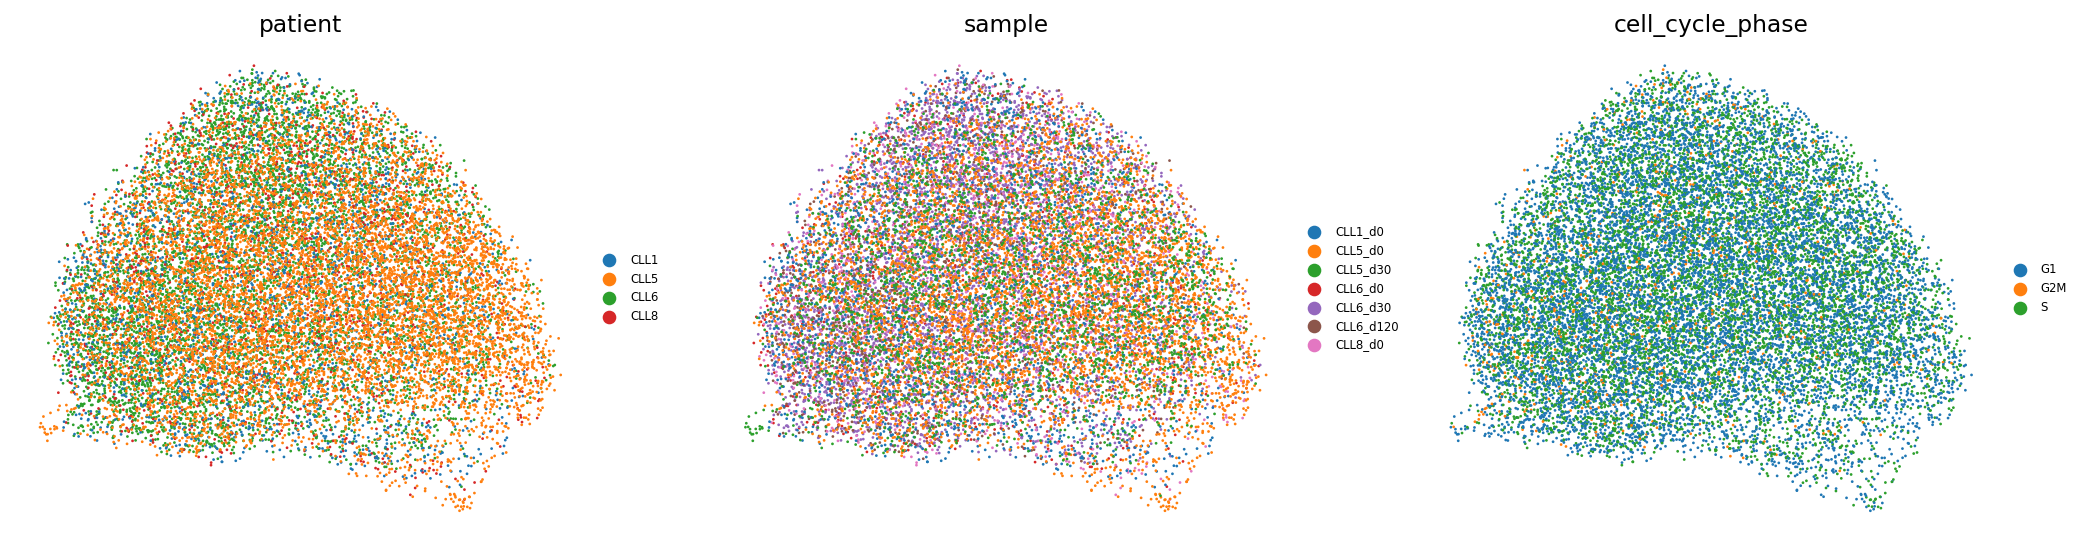

In [10]:
il_post_s = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
il_post_p = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['patient'].values))
print(f'iLISI median (theta={theta}): sample {il_pre_s:.2f}->{il_post_s:.2f}/{nsamp}, patient {il_pre_p:.2f}->{il_post_p:.2f}/{npat}')
print(f'{adata.shape[0]} cells on one connected component; 4 CLL clones intermix rather than forming per-patient islands')
print('GATE 1: samples/patients mix per-neighbourhood on one continuous manifold -> GO (within-patient axis confirmed in 02)')
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,col in zip(axes, ['patient','sample','cell_cycle_phase']):
    sc.pl.umap(plot, color=col, size=8, frameon=False, show=False, ax=ax, legend_fontsize=6, title=col)
fig.tight_layout(); plt.show()

### Save processed data

In [11]:
for c in list(adata.obs.columns):
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum()>0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (18490, 14889)


### `samples.pdf` — single sample-coloured manifold (house layout)

saved samples.pdf | cells: 18490


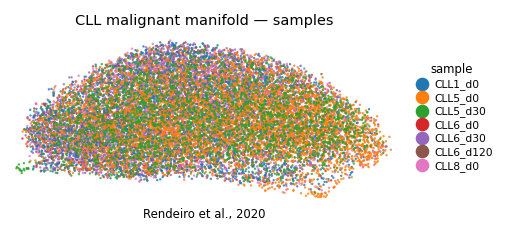

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('CLL malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])